Importing the libraries

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

print("All libraries imported successfully!")


All libraries imported successfully!


Imports the tools for data analysis, visualisation, feature selection, model training and evaluation.

Load the dataset

In [2]:

dataset = load_breast_cancer(as_frame=True)

# Store the predictor variables
X = dataset.data.copy()

# Convert the target so that:
# 0 = Benign
# 1 = Malignant
y = (dataset.target == 0).astype(int)

# Combine the data for initial inspection
df = X.copy()
df["Diagnosis"] = y.map({0: "Benign", 1: "Malignant"})

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Number of rows: 569
Number of columns: 31


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant


A table showing the first five observations, with measurements such as mean radius, mean texture and mean perimeter.

The dataset contains 569 observations and 30 numerical predictor features, plus the diagnosis target.

Explore the dataset

Check data types and structure

In [24]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [ ]:
This shows the column names, data types and number of non-null values. It helps identify unexpected data types and missing values.

Check for missing values

In [4]:


print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())


mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
Diagnosis                  0
dtype: int64

Total missing values: 0


Check for duplicate

In [5]:

print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


Generate descriptive statistics

In [6]:

X.describe().round(2)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,...,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10,0.09,0.05,0.18,0.06,...,16.27,25.68,107.26,880.58,0.13,0.25,0.27,0.11,0.29,0.08
std,3.52,4.30,24.30,351.91,0.01,0.05,0.08,0.04,0.03,0.01,...,4.83,6.15,33.60,569.36,0.02,0.16,0.21,0.07,0.06,0.02
min,6.98,9.71,43.79,143.50,0.05,0.02,0.00,0.00,0.11,0.05,...,7.93,12.02,50.41,185.20,0.07,0.03,0.00,0.00,0.16,0.06
25%,11.70,16.17,75.17,420.30,0.09,0.06,0.03,0.02,0.16,0.06,...,13.01,21.08,84.11,515.30,0.12,0.15,0.11,0.06,0.25,0.07
50%,13.37,18.84,86.24,551.10,0.10,0.09,0.06,0.03,0.18,0.06,...,14.97,25.41,97.66,686.50,0.13,0.21,0.23,0.10,0.28,0.08
75%,15.78,21.80,104.10,782.70,0.11,0.13,0.13,0.07,0.20,0.07,...,18.79,29.72,125.40,1084.00,0.15,0.34,0.38,0.16,0.32,0.09
max,28.11,39.28,188.50,2501.00,0.16,0.35,0.43,0.20,0.30,0.10,...,36.04,49.54,251.20,4254.00,0.22,1.06,1.25,0.29,0.66,0.21


Visualise the data (EDA)

Visualise the diagnosis distribution

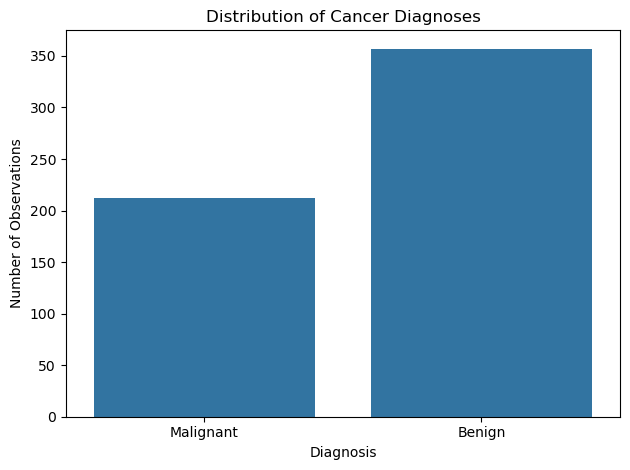

Diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


In [7]:

# Step 4.1: Count benign and malignant observations

sns.countplot(data=df, x="Diagnosis")

plt.title("Distribution of Cancer Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

print(df["Diagnosis"].value_counts())


Compare feature distributions

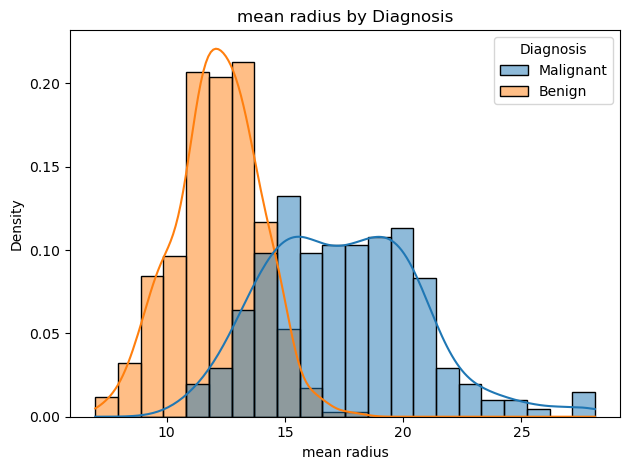

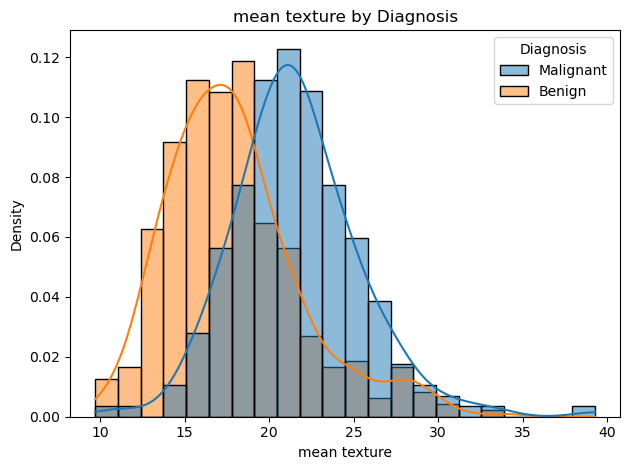

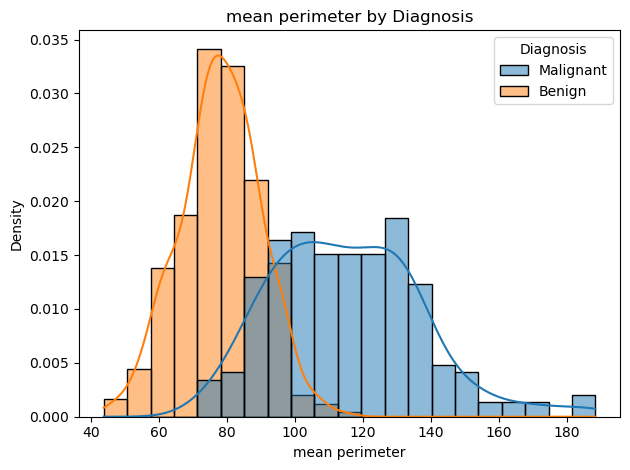

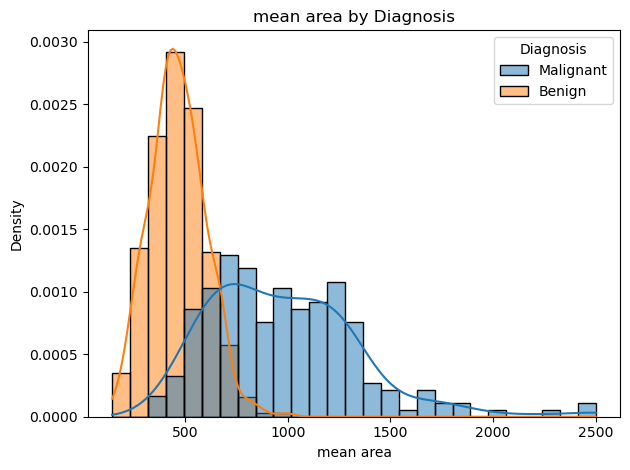

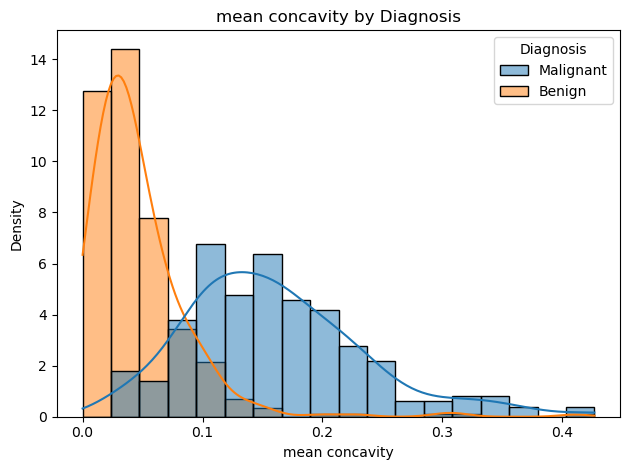

In [8]:

features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean concavity"
]

for feature in features:
    sns.histplot(
        data=df,
        x=feature,
        hue="Diagnosis",
        kde=True,
        stat="density",
        common_norm=False
    )

    plt.title(f"{feature} by Diagnosis")
    plt.tight_layout()
    plt.show()


These graphs help you see whether measurements have different distributions for benign and malignant observations. Write down the patterns you actually observe.

Create a correlation heatmap

In [ ]:

plt.figure(figsize=(14, 10))

correlation = X.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Heatmap of Cancer Features")
plt.tight_layout()
plt.show()


Strong positive correlations mean two features tend to increase together; strong negative correlations mean one tends to decrease as the other increases. Highly correlated features may contain overlapping information.

Prepare the data for training

In [10]:

# Remove duplicate predictor records, if present
duplicate_mask = X.duplicated()

X = X.loc[~duplicate_mask].copy()
y = y.loc[~duplicate_mask].copy()

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

print("Dataset shape after duplicate removal:", X.shape)
print("Missing predictor values:", X.isna().sum().sum())


Dataset shape after duplicate removal: (569, 30)
Missing predictor values: 0


The supplied dataset should not have missing predictor values. If your output shows missing values, address them before proceeding.

Split the dataset

In [11]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 455
Testing records: 114


80% training data: used to select features and train the model.



20% testing data: held back to evaluate the trained model.



stratify=y preserves approximately the same diagnosis proportions in both sets.



random_state=42 makes the split reproducible.

Select the best features

In [12]:

def make_pipeline(C=1.0, class_weight=None):
    return Pipeline([
        # Select 10 features using training data only
        ("selection", SelectKBest(score_func=f_classif, k=10)),

        # Standardise the selected features
        ("scaler", StandardScaler()),

        # Train Logistic Regression
        ("classifier", LogisticRegression(
            C=C,
            class_weight=class_weight,
            max_iter=5000,
            random_state=42
        ))
    ])

# Fit the baseline pipeline on training data
baseline = make_pipeline()

baseline.fit(X_train, y_train)

print("Baseline model trained successfully!")


Baseline model trained successfully!


The pipeline ensures that feature selection and standardisation are fitted using training data, rather than information from the test set.

Inspect the selected features

In [13]:

selector = baseline.named_steps["selection"]

feature_scores = pd.DataFrame({
    "Feature": X_train.columns,
    "F-score": selector.scores_,
    "P-value": selector.pvalues_
})

feature_scores = feature_scores.sort_values(
    by="F-score",
    ascending=False
)

print(feature_scores.head(10).to_string(index=False))

print("\nFeatures selected for training:")
print(list(X_train.columns[selector.get_support()]))


             Feature    F-score      P-value
worst concave points 733.724933 8.778594e-97
     worst perimeter 717.246487 2.093046e-95
        worst radius 692.861395 2.483688e-93
 mean concave points 684.526845 1.300875e-92
      mean perimeter 548.413236 4.687521e-80
          worst area 522.188947 1.932387e-77
         mean radius 511.274848 2.485053e-76
           mean area 444.857518 2.691158e-69
      mean concavity 397.592082 5.781926e-64
     worst concavity 319.507776 1.820808e-54

Features selected for training:
['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


Higher F-scores indicate stronger evidence of differences between the two diagnosis groups. The p-values provide additional statistical evidence, but they do not establish causation or clinical usefulness.

Evaluate the baseline model

In [14]:

# Step 7: Predict diagnoses on the test set

y_pred = baseline.predict(X_test)

# Predict probabilities of malignant classification
y_prob = baseline.predict_proba(X_test)[:, 1]

print("Predictions completed!")
print("First 10 actual labels:", y_test.iloc[:10].tolist())
print("First 10 predicted labels:", y_pred[:10].tolist())


Predictions completed!
First 10 actual labels: [0, 1, 0, 1, 0, 0, 1, 0, 0, 0]
First 10 predicted labels: [0, 1, 0, 1, 0, 0, 1, 0, 0, 0]


Calculate the performance metrics

In [15]:

# Calculate baseline performance metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

auc = roc_auc_score(y_test, y_prob)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

specificity = tn / (tn + fp)

print("Accuracy:", round(accuracy, 4))
print("Malignant precision:", round(precision, 4))
print("Malignant recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("Specificity:", round(specificity, 4))
print("ROC-AUC:", round(auc, 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))


Accuracy: 0.9561
Malignant precision: 0.9744
Malignant recall: 0.9048
F1-score: 0.9383
Specificity: 0.9861
ROC-AUC: 0.9974

Classification report:
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



Display the confusion matrix

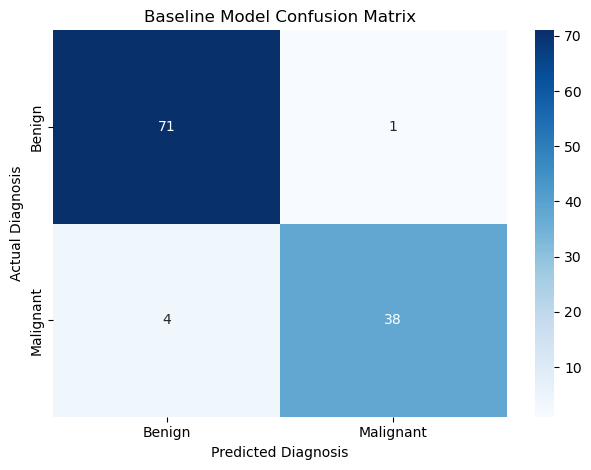

In [16]:

# Visualise the baseline confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.title("Baseline Model Confusion Matrix")
plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")
plt.tight_layout()
plt.show()


Improve the model

In [17]:

improved_pipeline = make_pipeline()

parameter_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}

search = GridSearchCV(
    estimator=improved_pipeline,
    param_grid=parameter_grid,
    scoring="recall",
    cv=5,
    n_jobs=-1
)

search.fit(X_train, y_train)

improved = search.best_estimator_

print("Best parameters:", search.best_params_)
print(
    "Best cross-validation malignant recall:",
    round(search.best_score_, 4)
)


Best parameters: {'classifier__C': 10, 'classifier__class_weight': 'balanced'}
Best cross-validation malignant recall: 0.9471


The model is selected using training data only. The test set remains untouched until final evaluation.

Evaluate the improved model

In [18]:

improved_pred = improved.predict(X_test)

improved_prob = improved.predict_proba(X_test)[:, 1]

tn, fp, fn, tp = confusion_matrix(
    y_test, improved_pred, labels=[0, 1]
).ravel()

improved_specificity = tn / (tn + fp)

print("Improved model evaluation")

print("Accuracy:", round(
    accuracy_score(y_test, improved_pred), 4
))

print("Malignant precision:", round(
    precision_score(y_test, improved_pred, zero_division=0), 4
))

print("Malignant recall:", round(
    recall_score(y_test, improved_pred, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_test, improved_pred, zero_division=0), 4
))

print("Specificity:", round(improved_specificity, 4))

print("ROC-AUC:", round(
    roc_auc_score(y_test, improved_prob), 4
))

print("\nClassification report:")
print(classification_report(
    y_test,
    improved_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))


Improved model evaluation
Accuracy: 0.9649
Malignant precision: 0.9524
Malignant recall: 0.9524
F1-score: 0.9524
Specificity: 0.9722
ROC-AUC: 0.9987

Classification report:
              precision    recall  f1-score   support

      Benign       0.97      0.97      0.97        72
   Malignant       0.95      0.95      0.95        42

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



Compare the two models

,Accuracy,Malignant Precision,Malignant Recall,F1-score,Specificity,ROC-AUC
Model,,,,,,
Baseline,0.9561,0.9744,0.9048,0.9383,0.9861,0.9974
Improved,0.9649,0.9524,0.9524,0.9524,0.9722,0.9987


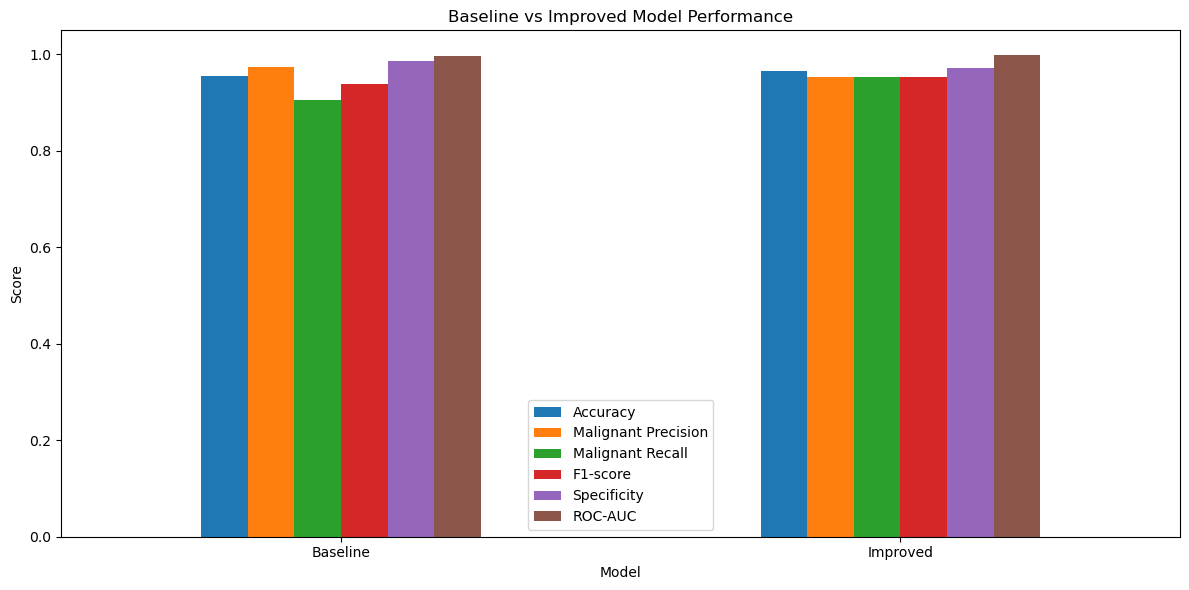

In [19]:

def get_metrics(model, name):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Malignant Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Malignant Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "ROC-AUC": roc_auc_score(y_test, prob)
    }

comparison = pd.DataFrame([
    get_metrics(baseline, "Baseline"),
    get_metrics(improved, "Improved")
])

comparison = comparison.set_index("Model")

display(comparison.round(4))

comparison.plot(kind="bar", figsize=(12, 6))

plt.title("Baseline vs Improved Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Plot the ROC curves

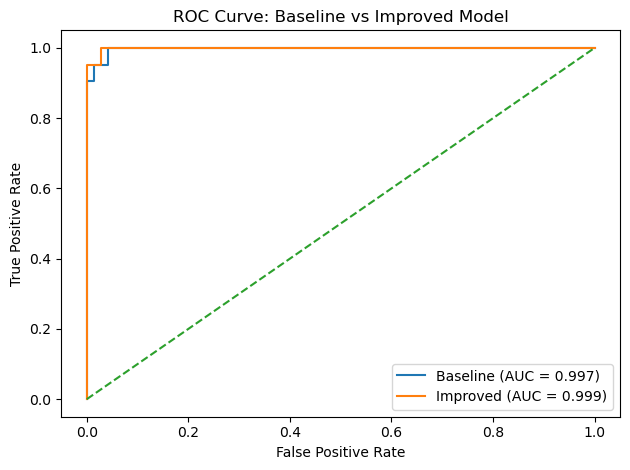

In [20]:

for name, model in [
    ("Baseline", baseline),
    ("Improved", improved)
]:
    probabilities = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, probabilities)

    auc_value = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Baseline vs Improved Model")
plt.legend()
plt.tight_layout()
plt.show()


Save results

In [21]:

comparison.to_csv("model_comparison.csv")

feature_scores.to_csv(
    "feature_selection_scores.csv",
    index=False
)

print("Results saved successfully!")


Results saved successfully!
